# Problem Set 2 — Solution — Advanced Data Analytics

**HEC Lausanne, autumn 2026** · Topics: pandas, multiple linear regression, Newton's method

Based on course materials by Prof. Simon Scheidegger.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


## Exercise 1 — Multiple regression: CO₂ emissions of cars

Multiple regression is linear regression with more than one explanatory
variable. The dataset `data/cars.csv` lists 36 car models with their engine
size (`Volume`, in cm³), weight (`Weight`, in kg), and CO₂ emissions
(`CO2`, in g/km).

We want to predict a car's CO₂ emissions from its weight **and** engine
volume:

$$\mathrm{CO_2} = \beta_0 + \beta_1\,\mathrm{Weight} + \beta_2\,\mathrm{Volume} + \varepsilon$$

### (a) Fit and predict

Load the data, build the feature matrix `X` (columns `Weight`, `Volume`) and
the target `y` (`CO2`), and fit a `sklearn.linear_model.LinearRegression`.
Then **predict the CO₂ emission of a car that weighs 2300 kg and has a
1300 cm³ engine**, and print the result.


In [2]:
df = pd.read_csv("data/cars.csv")

X = df[["Weight", "Volume"]]
y = df["CO2"]

model = LinearRegression()
model.fit(X, y)

# Predict with a DataFrame carrying the same column names as X:
# sklearn checks that feature names and order match what was fitted.
car = pd.DataFrame({"Weight": [2300], "Volume": [1300]})
pred = model.predict(car)[0]
print(f"Predicted CO2 for Weight=2300 kg, Volume=1300 cm^3: {pred:.3f} g/km")


Predicted CO2 for Weight=2300 kg, Volume=1300 cm^3: 107.209 g/km


### (b) Coefficients

Print the fitted coefficients and the intercept. Then answer in the markdown
cell below: **by how much does predicted CO₂ change when the weight
increases by 1 kg, holding engine volume fixed?**


In [3]:
for name, coef in zip(model.feature_names_in_, model.coef_):
    print(f"beta_{name}: {coef:.8f}")
print(f"intercept: {model.intercept_:.4f}")


beta_Weight: 0.00755095
beta_Volume: 0.00780526
intercept: 79.6947


**Answer.** The coefficient on `Weight` is a *partial* effect: holding engine
volume fixed, one extra kilogram raises predicted CO₂ by
$\beta_1 \approx 0.00755$ g/km. Note this is *not* the same as the slope you
would get from regressing CO₂ on weight alone — that simple regression would
also pick up the fact that heavier cars tend to have bigger engines.


### (c) Certify it

The model is linear, so it must obey a property you can check *exactly*:
the effect of +1000 kg is $1000 \cdot \beta_1$, no matter which car you
start from. **Contract check:** predict CO₂ for a car of **3300 kg** and
1300 cm³ and `assert` that the difference from your part-(a) prediction
equals $1000 \cdot \beta_1$ to within `1e-9`. If your assistant wrote
part (a) for you, this is where you find out whether it fitted what you
think it fitted.


In [4]:
car_heavy = pd.DataFrame({"Weight": [3300], "Volume": [1300]})
pred_heavy = model.predict(car_heavy)[0]

print(f"Predicted CO2 at 3300 kg:    {pred_heavy:.3f} g/km")
print(f"Difference vs part (a):      {pred_heavy - pred:.6f} g/km")
print(f"1000 * beta_Weight:          {1000 * model.coef_[0]:.6f} g/km")
assert abs((pred_heavy - pred) - 1000 * model.coef_[0]) < 1e-9
print("contract check passed: the model is exactly linear in Weight")


Predicted CO2 at 3300 kg:    114.760 g/km
Difference vs part (a):      7.550947 g/km
1000 * beta_Weight:          7.550947 g/km
contract check passed: the model is exactly linear in Weight


## Exercise 2 — Newton's method for a nonlinear system

Solve the following system with a **self-implemented** Newton's method, as
derived in the lecture — no `scipy.optimize` for the iteration itself:

$$\begin{aligned}
f_1(x_1, x_2) &= 5x_1^2 - x_2^2 = 0\\
f_2(x_1, x_2) &= x_2 - \tfrac{1}{4}\left(\sin x_1 + \cos x_2\right) = 0
\end{aligned}$$

Newton's method for systems: given an iterate $x^{(k)}$, solve the linear
system $J(x^{(k)})\, \delta = -f(x^{(k)})$ and set
$x^{(k+1)} = x^{(k)} + \delta$.

### (a) Derive the Jacobian

Write out the Jacobian $J(x) = \partial f_i / \partial x_j$ **by hand** in
the markdown cell below (double-click to edit; use LaTeX). Getting this on
paper first is the whole game — part (c) will show you why.


**Derivation.** Differentiating each component:

$$J(x_1, x_2) =
\begin{pmatrix}
\dfrac{\partial f_1}{\partial x_1} & \dfrac{\partial f_1}{\partial x_2}\\[1ex]
\dfrac{\partial f_2}{\partial x_1} & \dfrac{\partial f_2}{\partial x_2}
\end{pmatrix}
=
\begin{pmatrix}
10x_1 & -2x_2\\[1ex]
-\tfrac{1}{4}\cos x_1 & 1 + \tfrac{1}{4}\sin x_2
\end{pmatrix}$$

The two easy places to slip: the **minus sign** on $-2x_2$ (from
$-x_2^2$), and the $+\tfrac14 \sin x_2$ (the derivative of
$-\tfrac14\cos x_2$ flips the sign back to plus).


### (b) Implement Newton's method

Implement the iteration. Requirements:

- Solve $J\delta = -f$ with `np.linalg.solve` — **do not** form
  $J^{-1}$ with `np.linalg.inv`.
- Start from $x^{(0)} = (0.1,\, 0.1)$.
- Stop when $\lVert f(x^{(k)})\rVert < 10^{-12}$ or after 50 iterations.
- Record $\lVert f(x^{(k)})\rVert$ at every iteration for part (c).

Print the root and the number of iterations.

*Cross-check (allowed here):* `scipy.optimize.root` should agree with your
root to machine precision.


In [5]:
def f(x):
    return np.array([
        5 * x[0] ** 2 - x[1] ** 2,
        x[1] - 0.25 * (np.sin(x[0]) + np.cos(x[1])),
    ])


def jacobian(x):
    return np.array([
        [10 * x[0], -2 * x[1]],
        [-0.25 * np.cos(x[0]), 1 + 0.25 * np.sin(x[1])],
    ])


def newton(f, jac, x0, tol=1e-12, max_iter=50):
    x = np.asarray(x0, dtype=float)
    residuals = [np.linalg.norm(f(x))]
    for _ in range(max_iter):
        if residuals[-1] < tol:
            break
        delta = np.linalg.solve(jac(x), -f(x))
        x = x + delta
        residuals.append(np.linalg.norm(f(x)))
    return x, residuals


root, residuals = newton(f, jacobian, x0=(0.1, 0.1))
print(f"root: x1 = {root[0]:.6f}, x2 = {root[1]:.6f}")
print(f"iterations: {len(residuals) - 1}")
print(f"||f(root)|| = {residuals[-1]:.3e}")

from scipy.optimize import root as scipy_root

check = scipy_root(f, x0=[0.1, 0.1])
print(f"scipy.optimize.root agrees: {np.allclose(check.x, root)}")


root: x1 = 0.121242, x2 = 0.271105
iterations: 5
||f(root)|| = 9.146e-15
scipy.optimize.root agrees: True


### (c) Certify it: the verification contract

Your code from (b) prints a root. So would a subtly wrong implementation —
this is the central fact of numerical computing (and of working with AI
assistants). Two checks certify your work; each catches a classic mistake
that produces a perfectly plausible-looking answer.

**C1 — Jacobian vs. finite differences.** At 5 random points
$x \in [-1,1]^2$, compare every entry of `jacobian(x)` against a central
finite difference of `f`:
$\;J_{ij} \approx \bigl(f_i(x + h e_j) - f_i(x - h e_j)\bigr)/2h$ with
$h = 10^{-6}$. Report the maximum absolute error over all points and
entries — it should be $\sim 10^{-7}$ or smaller. A sign error in one
entry shows up as an error the size of the entry itself.

**C2 — Convergence rate.** Quadratic convergence means
$r_{k+1} \approx C\, r_k^2$ where $r_k = \lVert f(x^{(k)})\rVert$: the
ratio $r_{k+1}/r_k^2$ stays roughly constant while $r_{k+1}/r_k$
collapses. Plot $r_k$ on a log axis **and** print both ratio columns.
A merely-linear iteration (constant $r_{k+1}/r_k$) converges too — the
*rate* is what certifies your Jacobian and your update.


C1  max |J_analytic - J_fd| over 5 random points: 3.17e-10
C1  passed: the analytic Jacobian matches finite differences


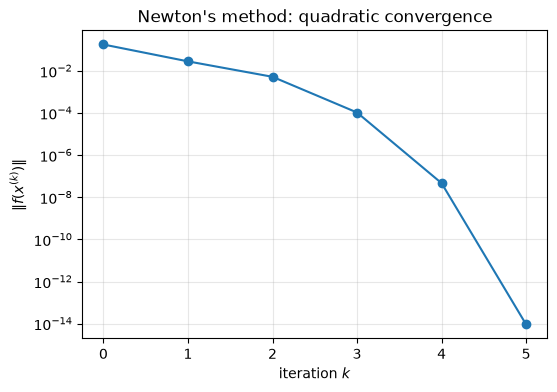

k    r_k          r_{k+1}/r_k    r_{k+1}/r_k^2
0    1.783e-01     1.582e-01     8.877e-01
1    2.821e-02     1.851e-01     6.561e+00
2    5.220e-03     2.017e-02     3.864e+00
3    1.053e-04     4.424e-04     4.201e+00
4    4.658e-08     1.964e-07     4.216e+00


In [6]:
def fd_jacobian(f, x, h=1e-6):
    n = len(x)
    J = np.zeros((n, n))
    for j in range(n):
        e = np.zeros(n)
        e[j] = h
        J[:, j] = (f(x + e) - f(x - e)) / (2 * h)
    return J


# --- C1: derivative check ---
rng = np.random.default_rng(0)
worst = 0.0
for _ in range(5):
    x_test = rng.uniform(-1, 1, size=2)
    worst = max(worst, np.abs(jacobian(x_test) - fd_jacobian(f, x_test)).max())
print(f"C1  max |J_analytic - J_fd| over 5 random points: {worst:.2e}")
assert worst < 1e-6, "Jacobian disagrees with finite differences"
print("C1  passed: the analytic Jacobian matches finite differences")

# --- C2: rate check ---
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(residuals, "o-")
ax.set_xlabel("iteration $k$")
ax.set_ylabel(r"$\|f(x^{(k)})\|$")
ax.set_title("Newton's method: quadratic convergence")
ax.grid(True, which="both", alpha=0.3)
plt.show()

print("k    r_k          r_{k+1}/r_k    r_{k+1}/r_k^2")
for k in range(len(residuals) - 1):
    rk, rk1 = residuals[k], residuals[k + 1]
    print(f"{k}    {rk:.3e}    {rk1 / rk:10.3e}    {rk1 / rk**2:10.3e}")


**Reading the table.** $r_{k+1}/r_k$ collapses ($10^{-1} \to 10^{-3} \to
10^{-7}$) while $r_{k+1}/r_k^2$ hovers around the same order of magnitude —
that is $r_{k+1} \approx C r_k^2$, quadratic convergence, the signature of
Newton's method with a correct Jacobian *and* a correct update. The number
of correct digits doubles every iteration; five iterations reach machine
precision. (The last row is at the floating-point floor, where the ratios
stop being meaningful.)

Why insist on the rate and not just on convergence? Because **any**
iteration $x \leftarrow x - M\,f(x)$ with an invertible matrix $M$ has the
true root as a fixed point — if it converges at all, it converges to the
*right answer*, no matter how wrong $M$ is. Converging proves nothing about
your Jacobian. The rate does. (Try it: flip the sign of one Jacobian entry
and rerun (b) — you will still land on the root, in about six times as
many iterations, and the $r_{k+1}/r_k$ column will stop collapsing.)


### (d) A start that cannot work

The origin looks like the most natural starting guess of all. **Try
$x^{(0)} = (0, 0)$. What happens, and why?** Look at $J(0,0)$ before you
blame your code.


In [7]:
print("J(0,0) =")
print(jacobian(np.array([0.0, 0.0])))
print(f"det J(0,0) = {np.linalg.det(jacobian(np.array([0.0, 0.0]))):.1f}")

try:
    newton(f, jacobian, x0=(0.0, 0.0))
except np.linalg.LinAlgError as e:
    print(f"newton() from (0,0) raises LinAlgError: {e}")


J(0,0) =
[[ 0.   -0.  ]
 [-0.25  1.  ]]
det J(0,0) = 0.0
newton() from (0,0) raises LinAlgError: Singular matrix


**Answer.** $J(0,0) = \begin{pmatrix} 0 & 0 \\ -\tfrac14 & 1 \end{pmatrix}$
has a zero first row, so $\det J = 0$ and the very first Newton step
$J\delta = -f$ has no (unique) solution — `np.linalg.solve` rightly raises
`LinAlgError: Singular matrix`. The first row is zero because both $5x_1^2$
and $x_2^2$ have vanishing gradients at the origin. Newton's method needs a
starting point where the Jacobian is invertible; any small perturbation
(such as $(0.1, 0.1)$) works here.


## Exercise 3 — Newton's method for $\sqrt{34}$

Compute $\sqrt{34}$ with your own scalar Newton iteration: formulate the
problem as finding the root of $f(x) = x^2 - 34$, start from $x^{(0)} = 6$,
and iterate until $|f(x^{(k)})| < 10^{-12}$. Compare with `np.sqrt(34)`.


In [8]:
x = 6.0
iterations = 0
while abs(x**2 - 34) >= 1e-12:
    x = x - (x**2 - 34) / (2 * x)
    iterations += 1

print(f"Newton's estimate of sqrt(34): {x:.15f}  ({iterations} iterations)")
print(f"np.sqrt(34):                   {np.sqrt(34):.15f}")
print(f"difference: {abs(x - np.sqrt(34)):.3e}")


Newton's estimate of sqrt(34): 5.830951894845320  (3 iterations)
np.sqrt(34):                   5.830951894845301
difference: 1.954e-14


**Remark.** This is the ancient *Babylonian method* in disguise: the Newton
update for $x^2 - a$ simplifies to $x \leftarrow \tfrac12(x + a/x)$. Three
iterations from $6$ already give all 16 digits — quadratic convergence
again.
